
# CODEALPHA INTERNSHIP - TASK 3

# DATA VISUALIZATION
## Project: Bike Sharing Dataset Analysis

### 1. Introduction

Data visualization is an essential part of data analysis.
It transforms complex datasets into visual representations
that help us understand patterns, trends and relationships.

This project uses the Bike Sharing dataset to explore
rental demand through different types of visualizations.

### 2. Project Objectives

- Analyze hourly bike rental patterns.
- Compare bike rentals across seasons.
- Explore the impact of weather conditions.
- Compare casual and registered users.
- Identify relationships between numerical variables.
- Create meaningful and informative visualizations.

### 3. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook


In [6]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All libraries imported successfully!")


All libraries imported successfully!



## 2. DATASET LOADING

The Bike Sharing dataset contains hourly rental records,
including dates, hours, seasons, weather conditions
and customer rental counts.

The original dataset from Task 2 is reused for this project.


In [7]:

# ==========================================
# 2. LOAD DATASET
# ==========================================

# Find the dataset from either notebook or workspace directory
possible_paths = [
    Path("Task2_EDA/hour.csv"),
    Path("../Task2_EDA/hour.csv")
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "hour.csv not found. Please check the Task2_EDA folder."
    )

df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print("Dataset location:", dataset_path.resolve())
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset location: C:\CodeAlpha\CodeAlpha_task2_EDA\Task2_EDA\hour.csv
Dataset shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [8]:

# ==========================================
# 3. DATASET OVERVIEW
# ==========================================

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing Values:
instant    

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



## 4. SEASONAL BIKE RENTAL ANALYSIS

Seasonal analysis helps us understand how bike rental
demand changes throughout the year.

In this section, we compare average hourly bike rentals
across Spring, Summer, Fall and Winter.

A bar chart will be used to visualize seasonal differences.


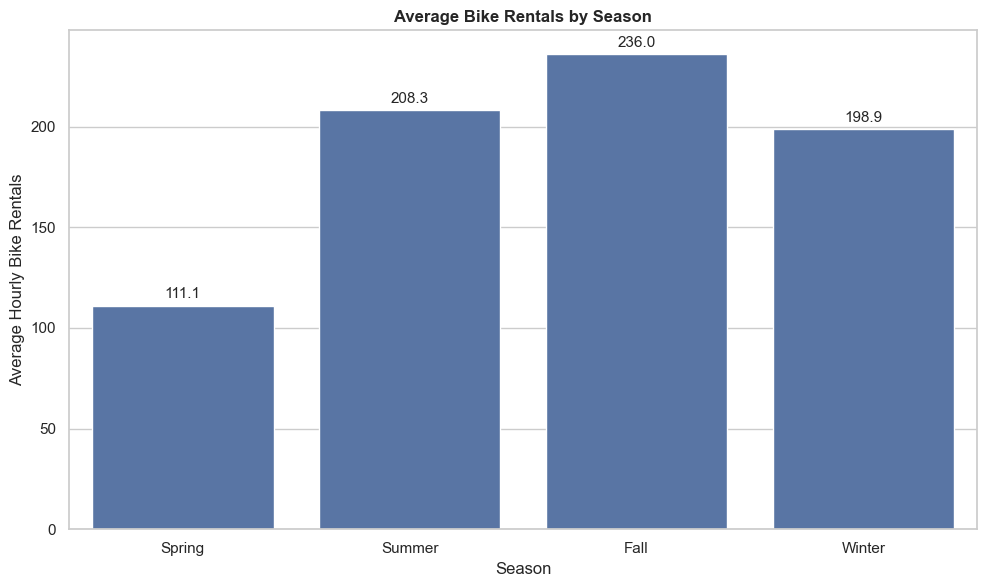

Seasonal visualization completed!


In [9]:

# ==========================================
# 4. SEASONAL BIKE RENTAL ANALYSIS
# ==========================================

# Define season labels
season_map = {
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
}

df['season_name'] = df['season'].map(season_map)

# Calculate average hourly rentals by season
seasonal_data = (
    df.groupby('season_name')['cnt']
    .mean()
    .reindex(['Spring', 'Summer', 'Fall', 'Winter'])
)

# Create bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=seasonal_data.index,
    y=seasonal_data.values
)

plt.title('Average Bike Rentals by Season',
          fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Average Hourly Bike Rentals')

# Add values above bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()

# Save chart
project_root = dataset_path.resolve().parent.parent
chart_folder = (
    project_root /
    'Task3_DataVisualization' /
    'outputs' /
    'charts'
)

chart_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    chart_folder / 'seasonal_rentals.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Seasonal visualization completed!")



## 5. HOURLY BIKE RENTAL ANALYSIS

This analysis explores how bike rental demand changes
throughout the 24 hours of a day.

An hourly line chart will help identify peak rental
periods and low-demand hours.


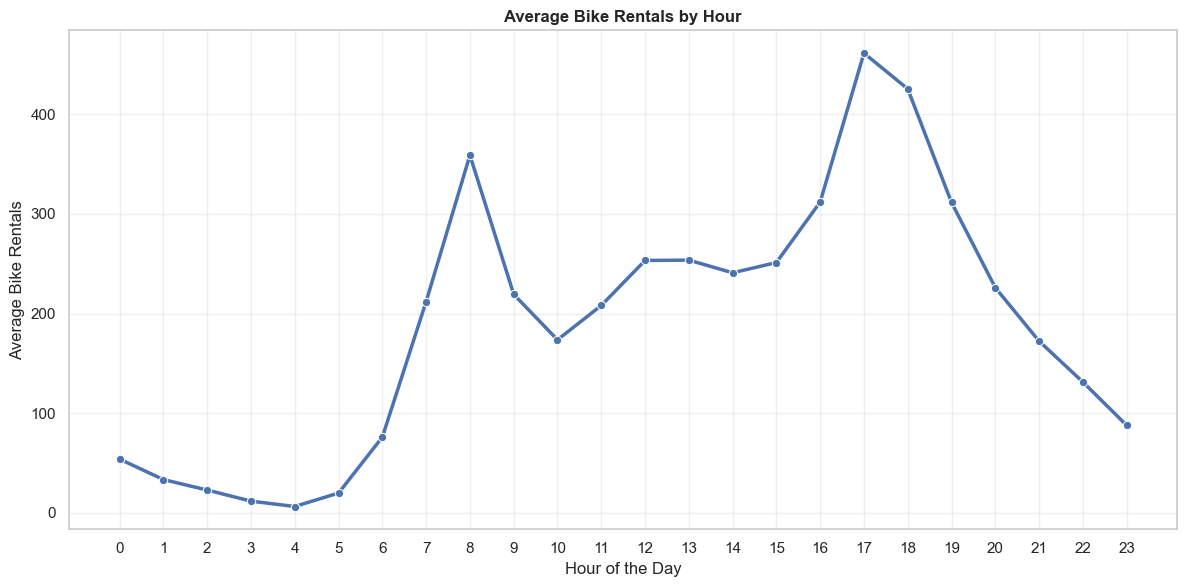

Hourly visualization completed!


In [11]:

# ==========================================
# 5. HOURLY BIKE RENTAL ANALYSIS
# ==========================================

hourly_data = df.groupby('hr')['cnt'].mean()

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_data.index,
    y=hourly_data.values,
    marker='o',
    linewidth=2.5
)

plt.title('Average Bike Rentals by Hour',
          fontweight='bold')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Bike Rentals')

plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    chart_folder / 'hourly_rentals.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Hourly visualization completed!")



## 6. USER TYPE COMPARISON

The Bike Sharing dataset contains two types of users:
casual users and registered users.

This analysis compares the total rentals contributed
by each user category using a bar chart.


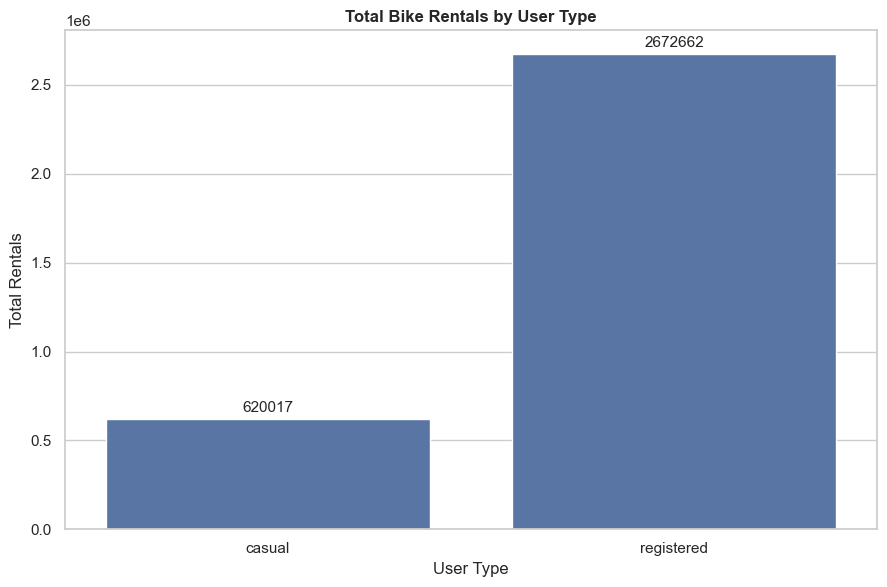

User type comparison completed!


casual         620017
registered    2672662
dtype: int64

In [12]:

# ==========================================
# 6. USER TYPE COMPARISON
# ==========================================

user_data = df[['casual', 'registered']].sum()

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=user_data.index,
    y=user_data.values
)

plt.title('Total Bike Rentals by User Type',
          fontweight='bold')
plt.xlabel('User Type')
plt.ylabel('Total Rentals')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()

plt.savefig(
    chart_folder / 'user_type_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("User type comparison completed!")
display(user_data)



## 7. WEATHER IMPACT ANALYSIS

Weather conditions can influence bike-sharing demand.

This analysis examines average bike rentals under
different weather conditions.

A bar chart is used to compare rental demand across
weather categories.


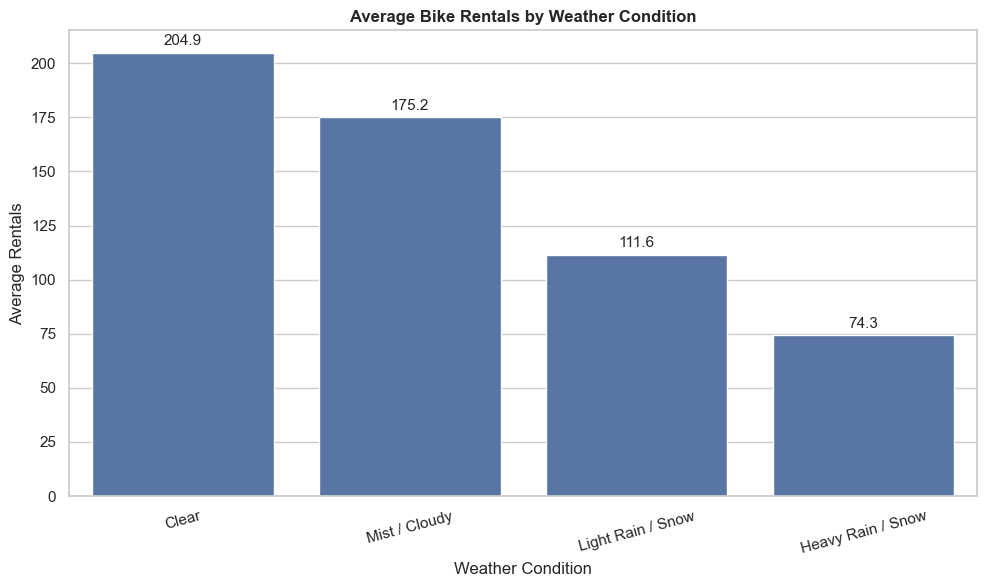

Weather analysis completed!


weather_name
Clear                204.869272
Mist / Cloudy        175.165493
Light Rain / Snow    111.579281
Heavy Rain / Snow     74.333333
Name: cnt, dtype: float64

In [13]:

# ==========================================
# 7. WEATHER IMPACT ANALYSIS
# ==========================================

weather_map = {
    1: 'Clear',
    2: 'Mist / Cloudy',
    3: 'Light Rain / Snow',
    4: 'Heavy Rain / Snow'
}

df['weather_name'] = df['weathersit'].map(weather_map)

weather_data = (
    df.groupby('weather_name')['cnt']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=weather_data.index,
    y=weather_data.values
)

plt.title('Average Bike Rentals by Weather Condition',
          fontweight='bold')
plt.xlabel('Weather Condition')
plt.ylabel('Average Rentals')

plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()

plt.savefig(
    chart_folder / 'weather_rentals.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Weather analysis completed!")
display(weather_data)



## 8. WORKING DAY COMPARISON

This analysis compares bike rental demand between
working days and non-working days.

It helps us understand how daily routines influence
bike-sharing usage.


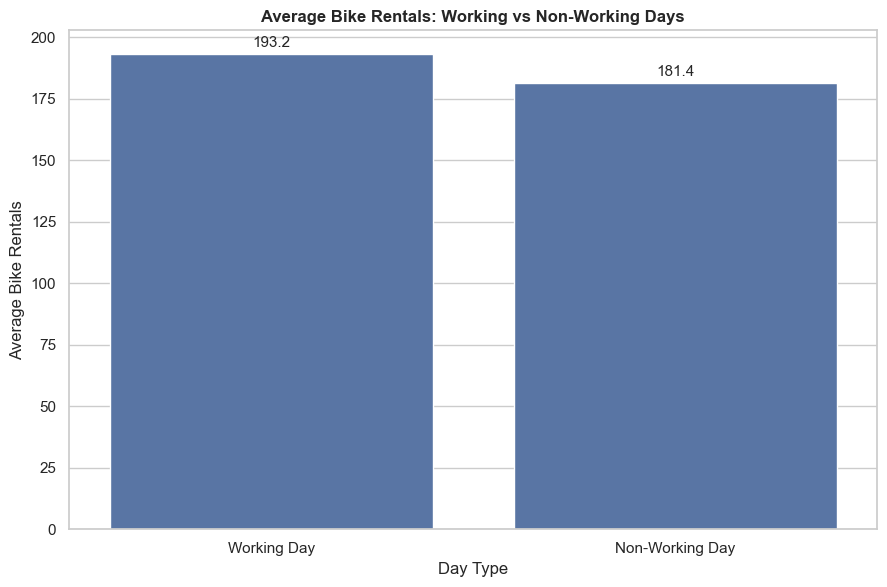

Working day comparison completed!


workingday_name
Working Day        193.207754
Non-Working Day    181.405332
Name: cnt, dtype: float64

In [14]:

# ==========================================
# 8. WORKING DAY COMPARISON
# ==========================================

workingday_map = {
    0: 'Non-Working Day',
    1: 'Working Day'
}

df['workingday_name'] = df['workingday'].map(workingday_map)

workingday_data = (
    df.groupby('workingday_name')['cnt']
    .mean()
    .reindex(['Working Day', 'Non-Working Day'])
)

plt.figure(figsize=(9, 6))

ax = sns.barplot(
    x=workingday_data.index,
    y=workingday_data.values
)

plt.title('Average Bike Rentals: Working vs Non-Working Days',
          fontweight='bold')
plt.xlabel('Day Type')
plt.ylabel('Average Bike Rentals')

for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)

plt.tight_layout()

plt.savefig(
    chart_folder / 'workingday_comparison.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Working day comparison completed!")
display(workingday_data)



## 9. RENTAL DISTRIBUTION ANALYSIS

A histogram is used to understand the distribution
of hourly bike rentals.

It helps identify the frequency of different rental
levels and understand the overall distribution
of bike-sharing demand.


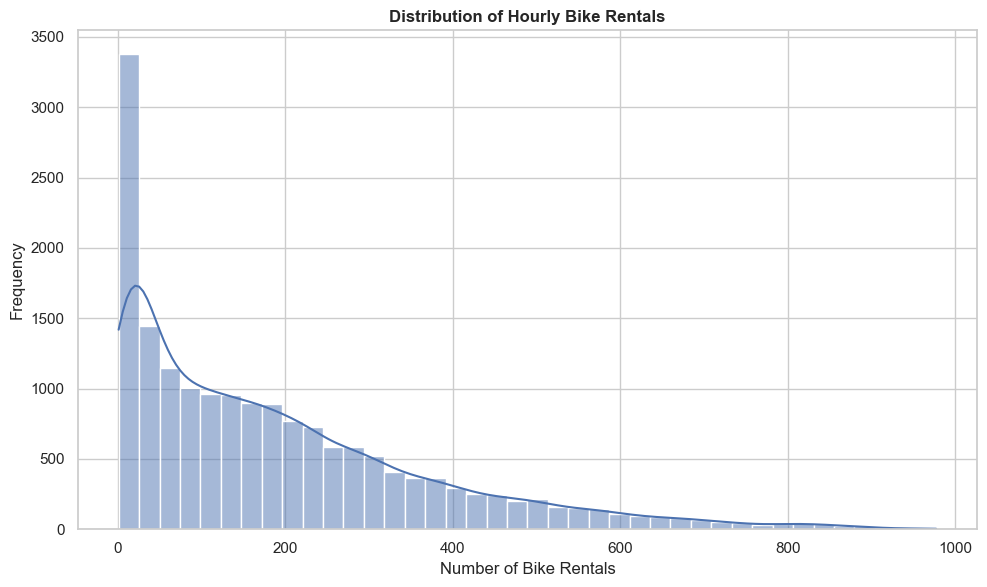

Rental distribution histogram completed!


In [15]:

# ==========================================
# 9. RENTAL DISTRIBUTION HISTOGRAM
# ==========================================

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='cnt',
    bins=40,
    kde=True
)

plt.title('Distribution of Hourly Bike Rentals',
          fontweight='bold')
plt.xlabel('Number of Bike Rentals')
plt.ylabel('Frequency')

plt.tight_layout()

plt.savefig(
    chart_folder / 'rental_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Rental distribution histogram completed!")



## 10. SEASONAL RENTAL DISTRIBUTION

A box plot helps compare the distribution of bike rentals
across different seasons.

It displays the median, spread and potential outliers
in hourly rental demand.


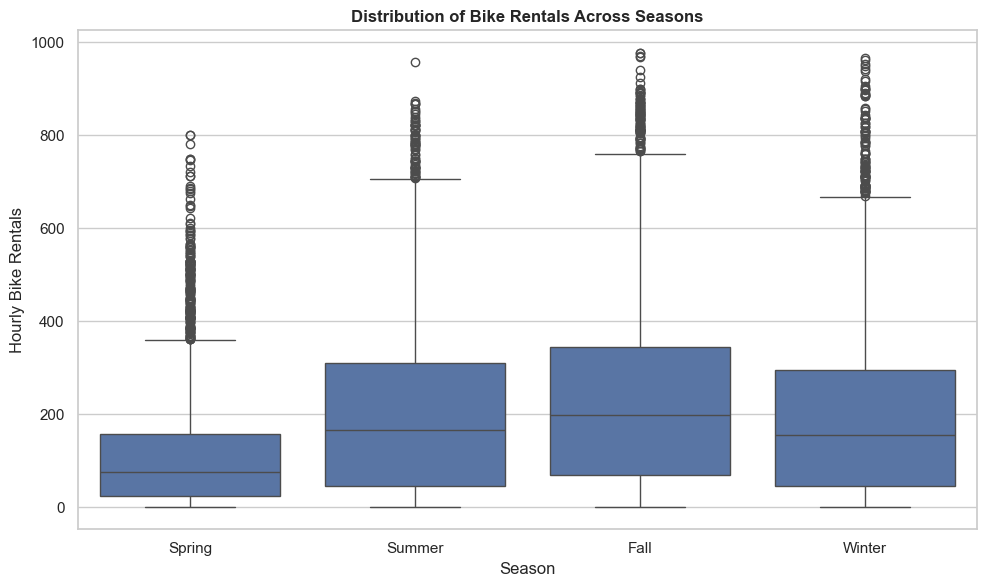

Seasonal box plot completed!


In [16]:

# ==========================================
# 10. SEASONAL RENTAL BOX PLOT
# ==========================================

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='season_name',
    y='cnt',
    order=['Spring', 'Summer', 'Fall', 'Winter']
)

plt.title('Distribution of Bike Rentals Across Seasons',
          fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Hourly Bike Rentals')

plt.tight_layout()

plt.savefig(
    chart_folder / 'seasonal_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Seasonal box plot completed!")



## 11. TEMPERATURE AND BIKE RENTAL RELATIONSHIP

This scatter plot explores the relationship between
temperature and hourly bike rental demand.

It helps us visually examine whether changes in
temperature are associated with changes in rentals.


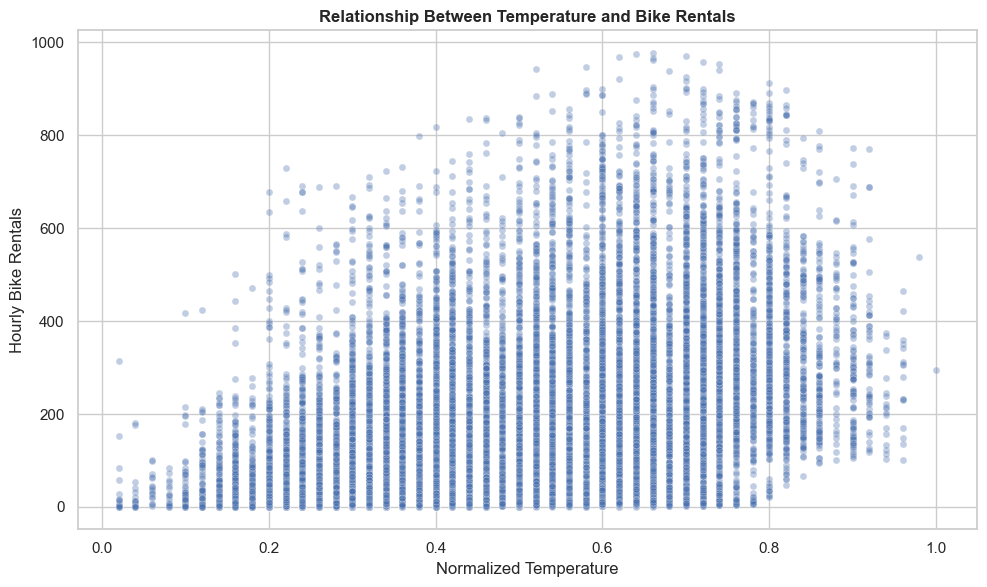

Temperature scatter plot completed!


In [17]:

# ==========================================
# 11. TEMPERATURE VS BIKE RENTALS
# ==========================================

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='temp',
    y='cnt',
    alpha=0.35,
    s=25
)

plt.title('Relationship Between Temperature and Bike Rentals',
          fontweight='bold')
plt.xlabel('Normalized Temperature')
plt.ylabel('Hourly Bike Rentals')

plt.tight_layout()

plt.savefig(
    chart_folder / 'temperature_scatterplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Temperature scatter plot completed!")



## 12. CORRELATION ANALYSIS

Correlation analysis helps identify relationships
between numerical variables in the Bike Sharing dataset.

A heatmap is used to visualize correlation coefficients
and understand how different variables are associated
with hourly bike rental demand.


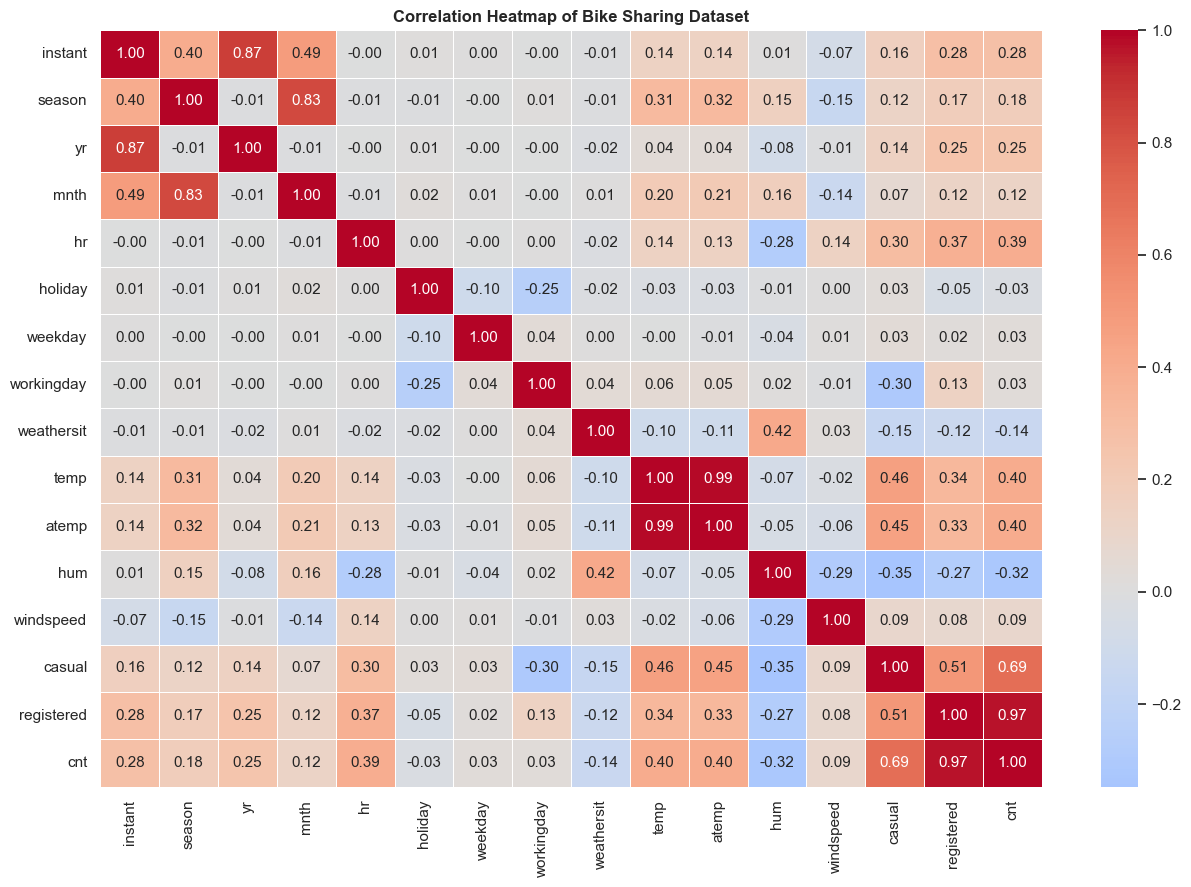

Correlation heatmap completed!


In [18]:

# ==========================================
# 12. CORRELATION HEATMAP
# ==========================================

numeric_df = df.select_dtypes(include=np.number)

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap of Bike Sharing Dataset',
          fontweight='bold')

plt.tight_layout()

plt.savefig(
    chart_folder / 'correlation_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Correlation heatmap completed!")


In [19]:

# ==========================================
# 13. VERIFY SAVED VISUALIZATIONS
# ==========================================

saved_charts = list(chart_folder.glob('*.png'))

print("TOTAL CHARTS CREATED:", len(saved_charts))
print("\nSAVED CHARTS:")

for chart in sorted(saved_charts):
    print("-", chart.name)

print("\nAll charts are saved successfully!")


TOTAL CHARTS CREATED: 9

SAVED CHARTS:
- correlation_heatmap.png
- hourly_rentals.png
- rental_distribution.png
- seasonal_boxplot.png
- seasonal_rentals.png
- temperature_scatterplot.png
- user_type_comparison.png
- weather_rentals.png
- workingday_comparison.png

All charts are saved successfully!



## 14. BIKE SHARING ANALYTICS DASHBOARD

This dashboard combines the major findings of the
Bike Sharing dataset into a single visual presentation.

It includes:
- Hourly rental demand
- Seasonal rental comparison
- User type comparison
- Weather impact analysis

The dashboard provides an overview of bike-sharing
patterns and supports data-driven decision-making.


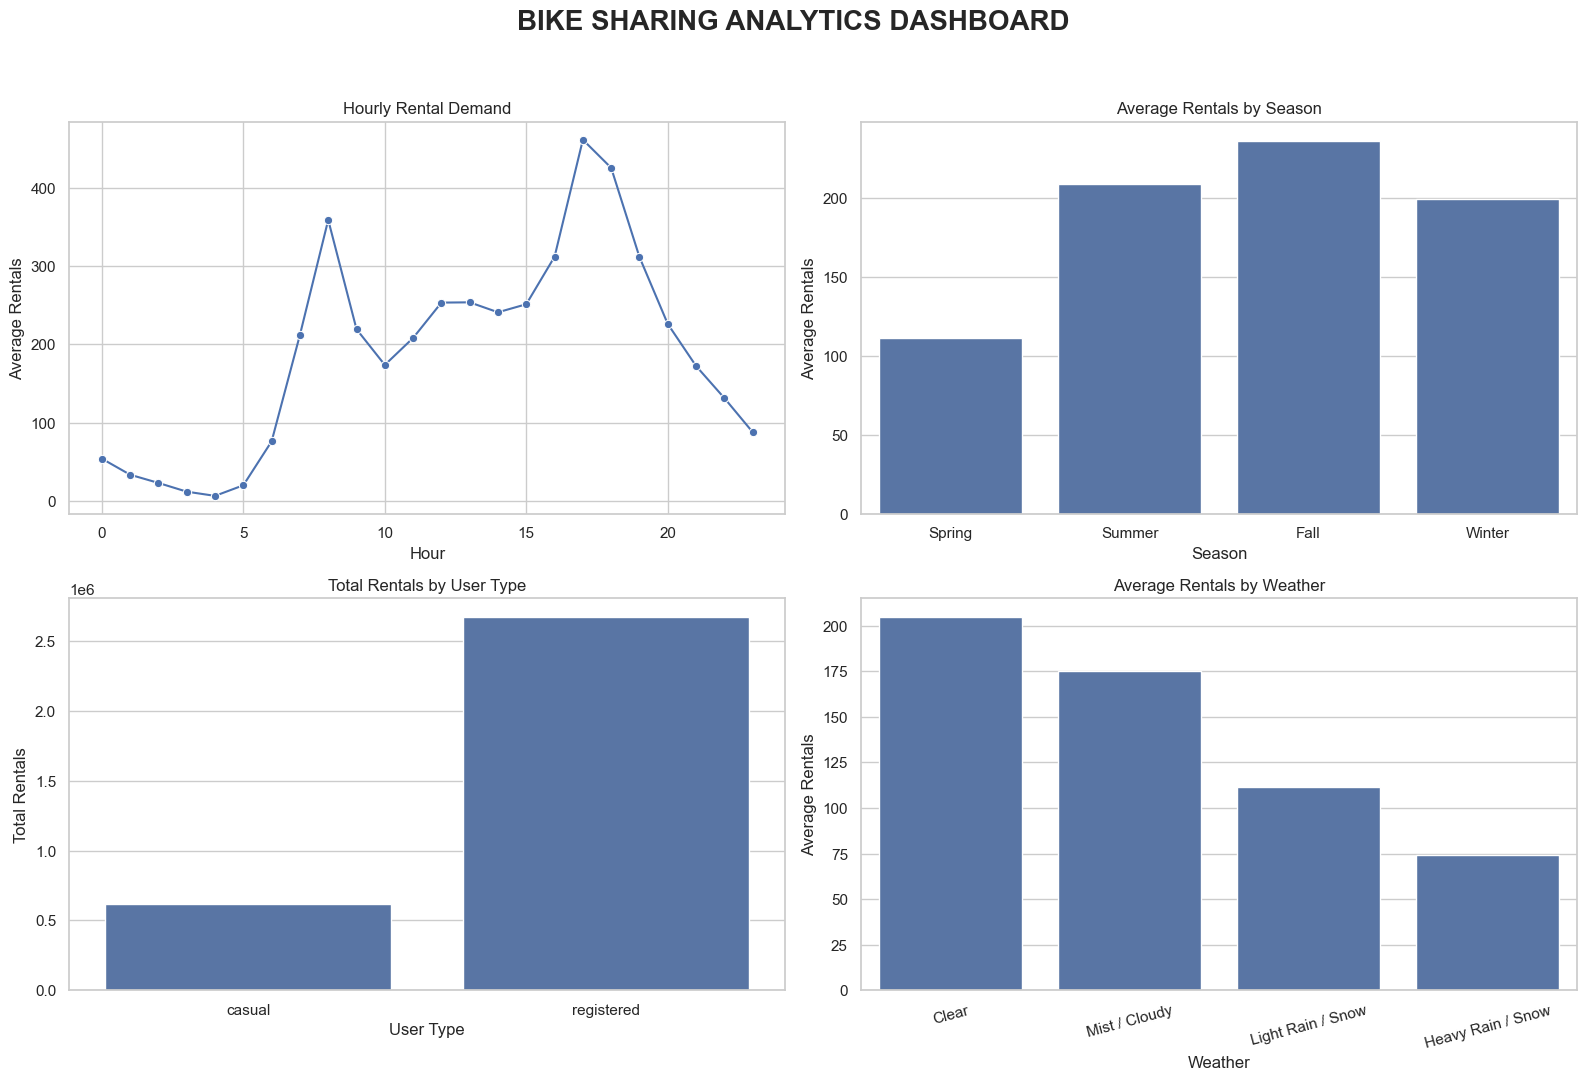

Dashboard created and saved successfully!


In [20]:

# ==========================================
# 14. BIKE SHARING ANALYTICS DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.suptitle(
    'BIKE SHARING ANALYTICS DASHBOARD',
    fontsize=20,
    fontweight='bold'
)

# 1. Hourly rental demand
sns.lineplot(
    x=hourly_data.index,
    y=hourly_data.values,
    marker='o',
    ax=axes[0, 0]
)
axes[0, 0].set_title('Hourly Rental Demand')
axes[0, 0].set_xlabel('Hour')
axes[0, 0].set_ylabel('Average Rentals')

# 2. Seasonal rentals
sns.barplot(
    x=seasonal_data.index,
    y=seasonal_data.values,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Average Rentals by Season')
axes[0, 1].set_xlabel('Season')
axes[0, 1].set_ylabel('Average Rentals')

# 3. User type comparison
sns.barplot(
    x=user_data.index,
    y=user_data.values,
    ax=axes[1, 0]
)
axes[1, 0].set_title('Total Rentals by User Type')
axes[1, 0].set_xlabel('User Type')
axes[1, 0].set_ylabel('Total Rentals')

# 4. Weather impact
sns.barplot(
    x=weather_data.index,
    y=weather_data.values,
    ax=axes[1, 1]
)
axes[1, 1].set_title('Average Rentals by Weather')
axes[1, 1].set_xlabel('Weather')
axes[1, 1].set_ylabel('Average Rentals')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    chart_folder / 'bike_sharing_dashboard.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Dashboard created and saved successfully!")


In [21]:

# ==========================================
# 15. KEY DATA INSIGHTS
# ==========================================

peak_hour = hourly_data.idxmax()
lowest_hour = hourly_data.idxmin()

best_season = seasonal_data.idxmax()
lowest_season = seasonal_data.idxmin()

best_weather = weather_data.idxmax()
lowest_weather = weather_data.idxmin()

registered_total = df['registered'].sum()
casual_total = df['casual'].sum()

registered_percentage = (
    registered_total / df['cnt'].sum()
) * 100

print("=" * 45)
print("BIKE SHARING - KEY ANALYTICAL FINDINGS")
print("=" * 45)

print(f"Peak rental hour: {peak_hour}:00")
print(f"Lowest rental hour: {lowest_hour}:00")

print(f"Highest-demand season: {best_season}")
print(f"Lowest-demand season: {lowest_season}")

print(f"Highest-demand weather: {best_weather}")
print(f"Lowest-demand weather: {lowest_weather}")

print(f"Registered user rentals: {registered_total:,}")
print(f"Casual user rentals: {casual_total:,}")

print(
    f"Registered user share: "
    f"{registered_percentage:.2f}%"
)

print("=" * 45)


BIKE SHARING - KEY ANALYTICAL FINDINGS
Peak rental hour: 17:00
Lowest rental hour: 4:00
Highest-demand season: Fall
Lowest-demand season: Spring
Highest-demand weather: Clear
Lowest-demand weather: Heavy Rain / Snow
Registered user rentals: 2,672,662
Casual user rentals: 620,017
Registered user share: 81.17%



## 16. KEY FINDINGS AND DATA INSIGHTS

Based on the exploratory visualizations and analysis,
the following insights were identified:

### 1. Hourly Rental Patterns
Bike rental demand varies significantly throughout
the day. The highest average rental demand occurs
at 5 PM (17:00), while the lowest occurs at 4 AM.

This suggests that commuting and daily activities
may influence bike-sharing usage.

### 2. Seasonal Rental Patterns
Fall records the highest average hourly rental demand,
while Spring records the lowest.

This indicates that seasonal conditions may be
associated with changes in customer demand.

### 3. User Type Analysis
Registered users account for approximately 81.17%
of total bike rentals, compared with casual users.

This demonstrates the importance of registered
customers to the bike-sharing service.

### 4. Weather Conditions
Clear weather records the highest average rental
demand, while Heavy Rain / Snow records the lowest.

This suggests that unfavorable weather conditions
may discourage bike-sharing activities.

### 5. Overall Observation
The analysis shows that bike rental demand is
associated with several factors, including time
of day, season, weather and customer type.

Understanding these patterns can help bike-sharing
operators make better operational decisions.



## 17. BUSINESS RECOMMENDATIONS

Based on the findings, the following recommendations
are proposed for bike-sharing operators:

### 1. Optimize Bike Availability
Operators should ensure sufficient bike availability
during peak hours, particularly around 5 PM.

### 2. Improve Seasonal Planning
More operational resources and maintenance planning
can be considered during high-demand seasons.

### 3. Focus on Customer Retention
Since registered users contribute approximately
81.17% of total rentals, operators should maintain
customer loyalty through membership benefits
and improved service quality.

### 4. Weather-Based Operations
Operators should monitor weather forecasts and
adjust bike distribution and maintenance schedules
during unfavorable weather conditions.

### 5. Improve Customer Experience
The service should focus on reliable bike availability,
convenient access and customer satisfaction to
encourage continued usage.

These recommendations aim to improve operational
efficiency, customer satisfaction and service planning.



## 18. PROJECT CONCLUSION

This project successfully explored and visualized
the Bike Sharing dataset using Python.

Using Pandas, NumPy, Matplotlib and Seaborn,
multiple visualizations were created to understand
rental patterns and customer behavior.

The analysis identified several important findings:

- Peak bike rental demand occurs at 5 PM.
- Fall has the highest average seasonal demand.
- Registered users contribute approximately 81.17%
  of total rentals.
- Clear weather is associated with higher rental demand.
- Rental demand varies throughout the day.

A combined analytical dashboard was also developed
to present the major findings in a clear and organized
format.

Overall, this project demonstrates how data
visualization can transform raw data into meaningful
insights that support business planning and
data-driven decision-making.

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook
